# **Staying on Top: Revenue Growth, Profitability and Five-Year Retention in the Fortune 500 (1955–2005)**

**Course:** AI-Powered Data Analysis using Python & Agile - EM Normandie (Prof. BOURAGA Sarah)

**Team:** CAUCHE Noé, CERULLO Giuliano, DESCOUBES Yan, GOUINGUENET Mathis, KETTANI Nasser

**Date:** 16/11/2026

**Dataset:** Fortune 500 companies, 1955–2005 - https://raw.githubusercontent.com/cybersamx/notebooks/master/data/fortune500.csv

## **1\. Introduction**

Author(s): CAUCHE Noé, CERULLO Giuliano, DESCOUBES Yan, GOUINGUENET Mathis, KETTANI Nasser

### **Problem statement**
The **Fortune 500** ranks the 500 largest U.S. companies by revenue each year. Being on the list is a sign of scale and market power, but the list changes constantly: every year some companies enter and others leave. This turnover is a **simple**, **observable measure of competition among large firms**.

In this project we use 51 years of rankings (1955–2005, 500 companies per year) to describe how companies grow, how profitable they are, and how often they are still on the list five years later.

### **Main research question**
*Are revenue growth and profitability associated with remaining in the Fortune 500 five years later, and has staying on the list become harder over time (1955–2005)?*

### **Why it matters**
- For managers and investors, being large today does not guarantee being large tomorrow. Knowing how often top companies stay at the top helps put a current ranking in context.
- If retention has fallen over time, competition among large firms may have become stronger.
- Looking at growth and profit together shows whether "doing well" in a given year is associated with staying on the list.

### **Definition of retention**
A company is **retained** (`survived_5y = True`) if it appears on the list in year *t* **and** in year *t + 5*.
- This does **not** mean the company was on the list every year in between.
- This does **not** mean the business survived or failed: an acquisition, a merger, a change of name or simply falling below rank 500 all show up as an apparent "exit".
- Because we need year *t + 5*, retention can only be measured for starting years 1955–2000.

### **Sub-questions**
1. **Growth:** How much do company revenues grow from one year to the next, and do larger companies grow more slowly?
2. **Profitability & risk:** Has the share of loss-making companies increased? Have profit margins become more dispersed? Which rank groups are most affected?
3. **Retention over time:** Has the five-year retention rate decreased over time?
4. **Growth, profit and retention:** Do growing and profitable companies appear more often on the list five years later?

### **Scope and caveat**
This is a **descriptive** analysis: data cleaning, feature engineering and exploratory data analysis. All results describe **associations** observed in the data ("X is associated with Y"); they do not show that one variable causes another.

## **2\. Packages required**

We use the following libraries:

- **pandas** (`pd`): to load the CSV file, clean the data, create new columns, filter, group (`groupby`) and combine tables (`merge`).
- **matplotlib.pyplot** (`plt`): to draw histograms, boxplots, line charts, bar charts and scatter plots, and to add titles, axis labels and legends.
- **seaborn** (`sns`): used only for the heatmaps (e.g. share of loss-making companies by decade and rank group).
- **numpy** (`np`): used only to compute the logarithm of revenue (np.log10) for the log-scale histogram.

In [ ]:
# Import the libraries used in this notebook
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

## **3\. Data Cleaning and Preparation**

### **3.1 Loading the data and first inspection**
We load the dataset directly from its URL, and look at its first rows to understand its structure.

In [ ]:
# Load the dataset from the URL
url = "https://raw.githubusercontent.com/cybersamx/notebooks/master/data/fortune500.csv"
df = pd.read_csv(url)
df.head()

,Year,Rank,Company,Revenue (in millions),Profit (in millions)
0,1955,1,General Motors,9823.5,806
1,1955,2,Exxon Mobil,5661.4,584.8
2,1955,3,U.S. Steel,3250.4,195.4
3,1955,4,General Electric,2959.1,212.6
4,1955,5,Esmark,2510.8,19.1


Author(s): CAUCHE Noé, CERULLO Giuliano, DESCOUBES Yan, GOUINGUENET Mathis, KETTANI Nasser

We check the size of the dataset (rows, columns) and the names of the columns.

In [ ]:
# Number of rows and columns
print(df.shape)

# Column names
print(df.columns)

(25500, 5)
Index(['Year', 'Rank', 'Company', 'Revenue (in millions)',
       'Profit (in millions)'],
      dtype='object')


Author(s): CAUCHE Noé, CERULLO Giuliano, DESCOUBES Yan, GOUINGUENET Mathis, KETTANI Nasser

We check the data type of each column. Numbers should be stored as `int64` or `float64`; text is stored as `object`.

In [ ]:
# Data type of each column
df.dtypes

,0
Year,int64
Rank,int64
Company,object
Revenue (in millions),float64
Profit (in millions),object


Author(s): CAUCHE Noé, CERULLO Giuliano, DESCOUBES Yan, GOUINGUENET Mathis, KETTANI Nasser

We count the missing values in each column and look at summary statistics for the numerical columns.

In [ ]:
# Missing values per column
print(df.isnull().sum())

Year                     0
Rank                     0
Company                  0
Revenue (in millions)    0
Profit (in millions)     0
dtype: int64


In [ ]:
# Summary statistics (only numerical columns are included)
df.describe()

,Year,Rank,Revenue (in millions)
count,25500.00000,25500.000000,25500.000000
mean,1980.00000,250.499765,4273.329635
std,14.71989,144.339963,11351.884979
min,1955.00000,1.000000,49.700000
25%,1967.00000,125.750000,362.300000
50%,1980.00000,250.500000,1019.000000
75%,1993.00000,375.250000,3871.000000
max,2005.00000,500.000000,288189.000000


### **3.2 Fixing the `Profit` column**

Author(s): CAUCHE Noé, CERULLO Giuliano, DESCOUBES Yan, GOUINGUENET Mathis, KETTANI Nasser

`Profit (in millions)` is stored as text (`object`) and is not included in `describe()`. This means that some values are not numbers. We look for the rows where the profit is written as `"N.A."` (not available).

In [ ]:
# Rows where the profit is the text "N.A."
na_rows = df[df["Profit (in millions)"] == "N.A."]
print(na_rows.shape)
na_rows.head()

(369, 5)


,Year,Rank,Company,Revenue (in millions),Profit (in millions)
228,1955,229,Norton,135.0,N.A.
290,1955,291,Schlitz Brewing,100.0,N.A.
294,1955,295,Pacific Vegetable Oil,97.9,N.A.
296,1955,297,Liebmann Breweries,96.0,N.A.
352,1955,353,Minneapolis-Moline,77.4,N.A.


Author(s): CAUCHE Noé, CERULLO Giuliano, DESCOUBES Yan, GOUINGUENET Mathis, KETTANI Nasser

We reload the file and tell pandas to treat `"N.A."` as a missing value. With this option (`na_values`), `Profit` becomes numeric and the 369 "N.A." values become real missing values (`NaN`). We do **not** delete these rows: they are excluded only from the analyses on profits.

In [ ]:
# Reload the data, treating "N.A." as a missing value
df = pd.read_csv(url, na_values=["N.A."])

print(df.dtypes)
print(df.isnull().sum())

Year                       int64
Rank                       int64
Company                   object
Revenue (in millions)    float64
Profit (in millions)     float64
dtype: object
Year                       0
Rank                       0
Company                    0
Revenue (in millions)      0
Profit (in millions)     369
dtype: int64


**Interpretation:** After reloading the file with `na_values=["N.A."]`, `Profit (in millions)` is stored as `float64` and has 369 missing values (out of 25,500 rows, about 1.4%). All other columns have no missing values. We keep these 369 rows in the dataset, because their year, rank, company and revenue are still valid; they will be excluded only from the analyses on profits.

**Interpretation:** The data covers the years [X min Year]–[X max Year]. Revenue ranges from [X min] to [X max] million $, with a mean of [X mean] and a median (50%) of [X 50%] million $. The mean is much higher than the median, which means that a few very large companies pull the average up: this is why we will mostly use the median. The minimum revenue is positive, so revenue growth can be computed for every company. `Profit` does not appear in this table because it is still stored as text.

### **3.3 Renaming the columns**

Author(s): CAUCHE Noé, CERULLO Giuliano, DESCOUBES Yan, GOUINGUENET Mathis, KETTANI Nasser

The original column names are long and contain spaces and brackets, which makes the code harder to write. We checked the order of the columns with `df.columns` (Year, Rank, Company, Revenue, Profit), so we replace them with short names in the same order. Revenue and profit are both in **millions of US dollars**.

In [ ]:
# Rename the columns (same order as the original ones)
df.columns = ["year", "rank", "company", "revenue", "profit"]
df.head()

,year,rank,company,revenue,profit
0,1955,1,General Motors,9823.5,806.0
1,1955,2,Exxon Mobil,5661.4,584.8
2,1955,3,U.S. Steel,3250.4,195.4
3,1955,4,General Electric,2959.1,212.6
4,1955,5,Esmark,2510.8,19.1


### **3.4 Checking the number of companies per year**

Author(s): CAUCHE Noé, CERULLO Giuliano, DESCOUBES Yan, GOUINGUENET Mathis, KETTANI Nasser

The Fortune 500 should contain exactly 500 companies every year. We count the companies in each year to check that no year is incomplete.

In [ ]:
# Number of companies in each year
companies_per_year = df.groupby("year")["company"].count()

print(companies_per_year.head())
print("Number of years:", companies_per_year.shape[0])
print("Minimum per year:", companies_per_year.min())
print("Maximum per year:", companies_per_year.max())

year
1955    500
1956    500
1957    500
1958    500
1959    500
Name: company, dtype: int64
Number of years: 51
Minimum per year: 500
Maximum per year: 500


**Interpretation:** The dataset covers 51 years (1955–2005) and every year contains exactly 500 companies. No year is incomplete.

### **3.5 Duplicate company-year pairs**

Author(s): CAUCHE Noé, CERULLO Giuliano, DESCOUBES Yan, GOUINGUENET Mathis, KETTANI Nasser

Later we will combine tables by matching the **company name** and the **year** (`merge`). This only works if each company appears at most once per year. We count how many times each (company, year) pair appears and keep the pairs that appear more than once.

In [ ]:
# Count how many times each (company, year) pair appears
pair_counts = df.groupby(["company", "year"])["rank"].count()

# Keep only the pairs that appear more than once
duplicate_pairs = pair_counts[pair_counts > 1]
print("Number of duplicate pairs:", duplicate_pairs.shape[0])
print(duplicate_pairs.head(10))

Number of duplicate pairs: 49
company  year
CBS      1972    2
         1973    2
         1974    2
         1975    2
         1976    2
         1977    2
         1978    2
         1979    2
         1980    2
         1981    2
Name: rank, dtype: int64


In [ ]:
# Number of duplicate years for each company name
pairs_by_name = duplicate_pairs.groupby("company").count()
print(pairs_by_name.sort_values(ascending=False))

company
Thiokol                  13
CBS                      11
OfficeMax                 8
Wachovia Corp.            7
U.S. Bancorp              5
Dean Foods                3
Chase Manhattan Corp.     2
Name: rank, dtype: int64


Author(s): CAUCHE Noé, CERULLO Giuliano, DESCOUBES Yan, GOUINGUENET Mathis, KETTANI Nasser

We inspect one case: CBS in 1975.

In [ ]:
# Example: the two "CBS" rows in 1975
df[(df["company"] == "CBS") & (df["year"] == 1975)]

,year,rank,company,revenue,profit
10018,1975,19,CBS,6466.1,28.1
10110,1975,111,CBS,1751.3,108.6


**Interpretation and decision:** 49 (company, year) pairs appear twice, for 7 company names (Thiokol 13 years, CBS 11, OfficeMax 8, Wachovia Corp. 7, U.S. Bancorp 5, Dean Foods 3, Chase Manhattan Corp. 2). For example, in 1975 "CBS" appears at rank 19 (revenue 6,466.1 million USD) and at rank 111 (revenue 1,751.3 million USD): these are two different companies with the same name in the list.

If we kept these names, a `merge` on company and year would match each row with both rows of the other year and multiply the number of rows, and we could not tell which company grew or stayed on the list.

**Our decision:** we keep these rows in the yearly descriptive statistics (each row is still a real company in the list), but we **exclude these 7 names** from the table used for growth and retention (`matchable`).

*Alternative:* remove only the 49 duplicate years instead of the whole names. This keeps more rows, but the same name could still refer to different companies in other years.

In [ ]:
# List of the 7 duplicated company names
duplicate_names = list(pairs_by_name.index)
print(duplicate_names)

# Table used for growth and retention: all companies except these names
matchable = df[df["company"].isin(duplicate_names) == False].copy()

print("Rows in df:", df.shape[0])
print("Rows in matchable:", matchable.shape[0])
print("Rows removed:", df.shape[0] - matchable.shape[0])

# Check: each (company, year) pair now appears only once
print("Max rows per pair:", matchable.groupby(["company", "year"])["rank"].count().max())

['CBS', 'Chase Manhattan Corp.', 'Dean Foods', 'OfficeMax', 'Thiokol', 'U.S. Bancorp', 'Wachovia Corp.']
Rows in df: 25500
Rows in matchable: 25262
Rows removed: 238
Max rows per pair: 1


**Interpretation:** Excluding the 7 duplicated names removes 238 rows (about 0.9% of the data). In `matchable` every (company, year) pair now appears only once, so the merges in the Feature Engineering section will not multiply rows.

### **3.6 Checking that revenue is always positive**

Author(s): CAUCHE Noé, CERULLO Giuliano, DESCOUBES Yan, GOUINGUENET Mathis, KETTANI Nasser

Revenue growth is computed as revenue / previous revenue. A revenue equal to zero or negative would make this calculation impossible or meaningless, so we check that there are no such values.

In [ ]:
# Rows with zero or negative revenue
print(df[df["revenue"] <= 0].shape)

(0, 5)


**Interpretation:** No company has zero or negative revenue (the minimum is 49.7 million USD), so revenue growth can be computed for every company that appears in two consecutive years.

### **3.7 Checkpoint: number of rows at each step**

Author(s): CAUCHE Noé, CERULLO Giuliano, DESCOUBES Yan, GOUINGUENET Mathis, KETTANI Nasser

We summarise how many rows we have after each clenaing step.

In [ ]:
# Rows with a known profit (used only for profit analyses)
profit_data = df[df["profit"].isnull() == False].copy()

checkpoint = pd.DataFrame({
    "step": ["Original file",
             "After reading 'N.A.' as missing",
             "After renaming columns",
             "matchable (duplicate names removed)",
             "profit_data (known profit only)"],
    "rows": [25500, df.shape[0], df.shape[0], matchable.shape[0], profit_data.shape[0]]
})
checkpoint

,step,rows
0,Original file,25500
1,After reading 'N.A.' as missing,25500
2,After renaming columns,25500
3,matchable (duplicate names removed),25262
4,profit_data (known profit only),25131


**Interpretation:** Cleaning does not delete any row from the main table `df` (25,500 rows). We create two filtered copies: `matchable` (25,262 rows) for growth and retention, and `profit_data` (25,131 rows, 369 missing profits excluded) for profit analyses.

## **4\. Feature Engineering**

Author(s): CAUCHE Noé, CERULLO Giuliano, DESCOUBES Yan, GOUINGUENET Mathis, KETTANI Nasser

We create six new variables to answer our sub-questions:

| Feature | Formula | Why |
|---|---|---|
| `profit_margin` | profit / revenue × 100 | Compares profitability of companies of different sizes (%) |
| `decade` | (year // 10) × 10 | Groups years to show long-term trends |
| `size_group` | rank cut into 1-100, …, 401-500 | Compares large and smaller companies in the list |
| `loss_flag` | profit < 0 | Identifies loss-making companies (only rows with known profit) |
| `revenue_growth` | (revenue / previous year revenue − 1) × 100 | Measures growth from one year to the next (%) |
| `survived_5y` | company present in year t and in year t+5 | Measures five-year retention |

### **4.1 Profit margin, decade and size group**

Author(s): CAUCHE Noé, CERULLO Giuliano, DESCOUBES Yan, GOUINGUENET Mathis, KETTANI Nasser

- **Profit margin (%)**: profit divided by revenue, times 100. A company with a missing profit gets a missing margin (`NaN`), not zero.
- **Decade**: `year // 10` keeps only the tens (e.g. 1987 // 10 = 198), then × 10 gives 1980.
- **Size group**: `pd.cut` puts each rank into one of five groups of 100 positions (rank 1–100 = the largest companies).

In [ ]:
# Profit margin in %
df["profit_margin"] = df["profit"] / df["revenue"] * 100

# Decade (e.g. 1987 -> 1980)
df["decade"] = (df["year"] // 10) * 10

# Size group based on rank
df["size_group"] = pd.cut(df["rank"],
                          bins=[0, 100, 200, 300, 400, 500],
                          labels=["1-100", "101-200", "201-300", "301-400", "401-500"])

df.head()

,year,rank,company,revenue,profit,profit_margin,decade,size_group
0,1955,1,General Motors,9823.5,806.0,8.204815,1950,1-100
1,1955,2,Exxon Mobil,5661.4,584.8,10.329600,1950,1-100
2,1955,3,U.S. Steel,3250.4,195.4,6.011568,1950,1-100
3,1955,4,General Electric,2959.1,212.6,7.184617,1950,1-100
4,1955,5,Esmark,2510.8,19.1,0.760714,1950,1-100


In [ ]:
# Check: number of rows per decade and per size group
print(df.groupby("decade")["company"].count())

# observed=True: show only the groups that exist (option not shown in slides)
print(df.groupby("size_group", observed=True)["company"].count())

decade
1950    2500
1960    5000
1970    5000
1980    5000
1990    5000
2000    3000
Name: company, dtype: int64
size_group
1-100      5100
101-200    5100
201-300    5100
301-400    5100
401-500    5100
Name: company, dtype: int64


**Interpretation:** The 1950s contain only 5 years (1955–1959, 2,500 rows) and the 2000s only 6 years (2000–2005, 3,000 rows); the other decades are complete (5,000 rows). Each size group contains 5,100 rows (100 ranks × 51 years). We must remember that the first and last decades are incomplete when comparing decades.

### **4.2 Loss flag**

Author(s): CAUCHE Noé, CERULLO Giuliano, DESCOUBES Yan, GOUINGUENET Mathis, KETTANI Nasser

We recreate `profit_data` (rows with a known profit) so that it also contains the new columns, and we add `loss_flag` = True when profit is negative. We create it only on `profit_data`, because a missing profit must never be counted as a profit or as a loss.

In [ ]:
# Recreate profit_data with the new columns
profit_data = df[df["profit"].isnull() == False].copy()

# True if the company made a loss
profit_data["loss_flag"] = profit_data["profit"] < 0

print("Rows in profit_data:", profit_data.shape[0])
print("Loss-making rows:", profit_data["loss_flag"].sum())
print("Share of losses (%):", profit_data["loss_flag"].mean() * 100)

Rows in profit_data: 25131
Loss-making rows: 2005
Share of losses (%): 7.97819426206677


**Interpretation:** Among the 25,131 rows with a known profit, 2,005 (about 8.0%) show a loss. Over the whole period, losses are therefore uncommon among Fortune 500 companies; in the EDA we check whether this share changed over time.

### **4.3 Revenue growth (merge with the previous year)**

Author(s): CAUCHE Noé, CERULLO Giuliano, DESCOUBES Yan, GOUINGUENET Mathis, KETTANI Nasser

To compute growth we need, on the same row, the revenue of year t and the revenue of year t−1 of the same company. We:
1. recreate `matchable` (without the 7 duplicated names) so it contains the new columns;
2. copy `company, year, revenue, rank, size_group` and rename them `previous_*`;
3. **add 1 to the year**: the revenue of 1955 is now labelled 1956, so it sits next to the 1956 revenue when we merge on company and year;
4. merge with `how="inner"`: we keep only companies present in **two consecutive years**.

1955 has no growth because we do not have 1954 data. The size group is measured **before** the growth (`previous_size_group`).

In [ ]:
# Recreate matchable with the new columns
matchable = df[df["company"].isin(duplicate_names) == False].copy()

# Table of the previous year
previous = matchable[["company", "year", "revenue", "rank", "size_group"]].copy()
previous.columns = ["company", "year", "previous_revenue", "previous_rank", "previous_size_group"]
previous["year"] = previous["year"] + 1

previous.head()

,company,year,previous_revenue,previous_rank,previous_size_group
0,General Motors,1956,9823.5,1,1-100
1,Exxon Mobil,1956,5661.4,2,1-100
2,U.S. Steel,1956,3250.4,3,1-100
3,General Electric,1956,2959.1,4,1-100
4,Esmark,1956,2510.8,5,1-100


In [ ]:
# Merge: each row gets the revenue of the same company in the previous year
growth = matchable.merge(previous, on=["company", "year"], how="inner")

# Revenue growth in %
growth["revenue_growth"] = (growth["revenue"] / growth["previous_revenue"] - 1) * 100

print("Rows in growth:", growth.shape[0])
print("Years:", growth["year"].min(), "-", growth["year"].max())
print(growth["revenue_growth"].describe())

Rows in growth: 22944
Years: 1956 - 2005
count    22944.000000
mean         9.611684
std         17.942911
min        -92.125924
25%          1.095491
50%          7.860291
75%         15.371247
max        366.917148
Name: revenue_growth, dtype: float64


**Interpretation:** We can measure growth for 22,944 company-years (1956–2005), i.e. only when a company appears in two consecutive years. The median growth is 7.9% per year and the mean 9.6%: the mean is higher because a few extreme values (up to +367%, down to −92%) pull it up. We will therefore use the median in the EDA. Revenues are nominal (not adjusted for inflation), so part of this growth reflects price increases.

### **4.4 Five-year retention (merge with year t+5)**

Author(s): CAUCHE Noé, CERULLO Giuliano, DESCOUBES Yan, GOUINGUENET Mathis, KETTANI Nasser

For each company in year t we want to know if it is on the list in year t+5. We:
1. copy `company, year` from `matchable` and **subtract 5 from the year**: an appearance in 1960 becomes 1955, so it matches the 1955 row;
2. add a marker column equal to 1;
3. keep only starting years **≤ 2000**: for 2001–2005 we do not have year t+5 (data stops in 2005);
4. merge with `how="left"`: we keep all starting rows; if the company is not found five years later the marker is missing.

In [ ]:
# Table of the year t+5, shifted back by 5 years
future = matchable[["company", "year"]].copy()
future["year"] = future["year"] - 5
future["in_list_5y_later"] = 1

# Starting years: only up to 2000
start = matchable[matchable["year"] <= 2000].copy()

# Left merge: keep all starting rows
retention = start.merge(future, on=["company", "year"], how="left")
retention["survived_5y"] = retention["in_list_5y_later"].isnull() == False

print("Rows before merge:", start.shape[0])
print("Rows after merge:", retention.shape[0])
print("Retention rate (%):", retention["survived_5y"].mean() * 100)

Rows before merge: 22790
Rows after merge: 22790
Retention rate (%): 74.62483545414655


**Interpretation:** The left merge keeps exactly the same number of rows (22,790), which confirms that each company-year is matched at most once. Over 1955–2000, about 74.6% of companies on the list are also on the list five years later; about one in four is not (because it fell below rank 500, was acquired, merged or changed name).

### **4.5 Manual checks**

Author(s): CAUCHE Noé, CERULLO Giuliano, DESCOUBES Yan, GOUINGUENET Mathis, KETTANI Nasser

We verify each new feature on real examples by looking at the original data.

In [ ]:
# Check 1: profit margin of General Motors in 1955 (by hand: 806 / 9823.5 * 100)
print("By hand:", 806 / 9823.5 * 100)
print(df[(df["company"] == "General Motors") & (df["year"] == 1955)][["revenue", "profit", "profit_margin"]])

By hand: 8.204814984476002
   revenue  profit  profit_margin
0   9823.5   806.0       8.204815


In [ ]:
# Check 2: growth of General Motors from 1955 to 1956
print(df[(df["company"] == "General Motors") & (df["year"] <= 1956)][["year", "revenue"]])
print("By hand:", (12443.3 / 9823.5 - 1) * 100)
print(growth[(growth["company"] == "General Motors") & (growth["year"] == 1956)][["previous_revenue", "revenue", "revenue_growth"]])

     year  revenue
0    1955   9823.5
500  1956  12443.3
By hand: 26.66870260090599
   previous_revenue  revenue  revenue_growth
0            9823.5  12443.3       26.668703


In [ ]:
# Check 3: a True case (General Motors is on the list in 1955 and in 1960)
print(df[(df["company"] == "General Motors") & (df["year"].isin([1955, 1960]))][["year", "rank", "company"]])

# Check 4: a False case (Briggs Manufacturing appears only in 1955)
print(df[df["company"] == "Briggs Manufacturing"][["year", "rank", "company"]])
print(retention[(retention["company"].isin(["General Motors", "Briggs Manufacturing"])) & (retention["year"] == 1955)][["company", "year", "survived_5y"]])

      year  rank         company
0     1955     1  General Motors
2500  1960     1  General Motors
    year  rank               company
64  1955    65  Briggs Manufacturing
                 company  year  survived_5y
0         General Motors  1955         True
63  Briggs Manufacturing  1955        False


**Interpretation:** All manual checks match the computed features:
- General Motors 1955: 806 / 9,823.5 × 100 = 8.20%, equal to `profit_margin`.
- General Motors grew from 9,823.5 (1955) to 12,443.3 million USD (1956): +26.7%, equal to `revenue_growth`.
- General Motors is on the list in 1955 and 1960 → `survived_5y` = True.
- Briggs Manufacturing appears only in 1955 → `survived_5y` = False.

## **5\. Exploratory Data Analysis**


### **5.1 Overview of the data**

Author(s): CAUCHE Noé, CERULLO Giuliano, DESCOUBES Yan, GOUINGUENET Mathis, KETTANI Nasser

We first look at the distribution of revenue. Revenue is in **millions of US dollars, nominal** (not adjusted for inflation).

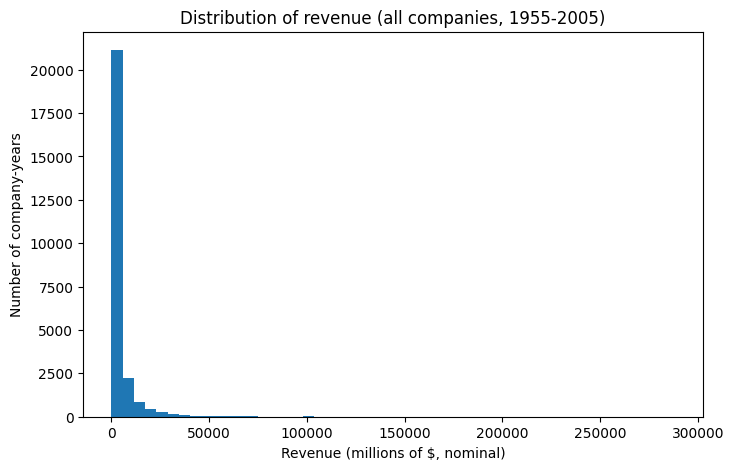

In [ ]:
# Histogram of revenue
plt.figure(figsize=(8, 5))
plt.hist(df["revenue"], bins=50)
plt.title("Distribution of revenue (all companies, 1955-2005)")
plt.xlabel("Revenue (millions of $, nominal)")
plt.ylabel("Number of company-years")
plt.show()

**Interpretation:** The distribution is extremely right-skewed: almost all company-years are on the left, and a few giants reach up to 288,189 million USD. The median (1,019 million USD) is much smaller than the mean (4,273 million USD). Because the chart is hard to read, we also plot revenue on a logarithmic scale.

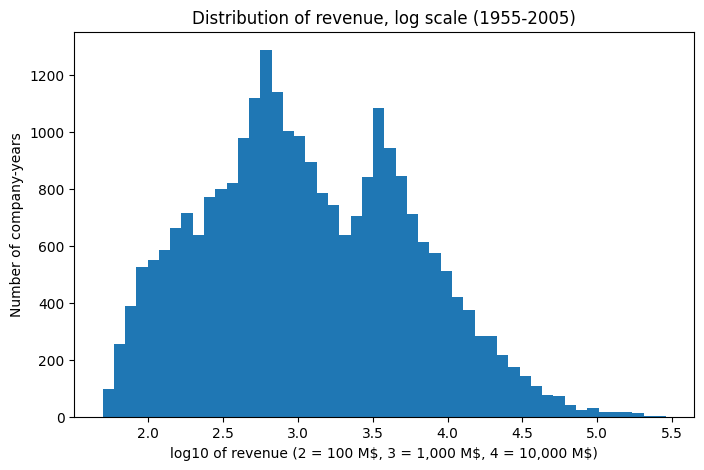

In [ ]:
# Histogram of revenue on a log scale (log10: 2 = 100 M$, 3 = 1,000 M$, 4 = 10,000 M$)
plt.figure(figsize=(8, 5))
plt.hist(np.log10(df["revenue"]), bins=50)
plt.title("Distribution of revenue, log scale (1955-2005)")
plt.xlabel("log10 of revenue (2 = 100 M$, 3 = 1,000 M$, 4 = 10,000 M$)")
plt.ylabel("Number of company-years")
plt.show()

**Interpretation:** On the log scale the distribution is much easier to read. Most company-years have revenues between about 100 million USD (log10 = 2) and 10,000 million USD (log10 = 4). The chart shows two peaks, around 600 million USD and around 4,000 million USD. This is likely associated with the general increase of nominal revenues over time (the same rank corresponds to much higher revenue in later years), which we check below.

Author(s): CAUCHE Noé, CERULLO Giuliano, DESCOUBES Yan, GOUINGUENET Mathis, KETTANI Nasser

We look at the distribution of the profit margin (only rows with a known profit) with a boxplot.

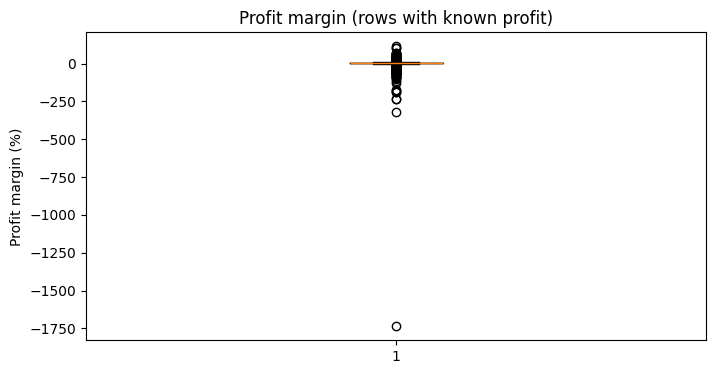

In [ ]:
# Boxplot of profit margin
plt.figure(figsize=(8, 4))
plt.boxplot(profit_data["profit_margin"])
plt.title("Profit margin (rows with known profit)")
plt.ylabel("Profit margin (%)")
plt.show()

**Interpretation:** The box is very compressed because of a few extreme values (the minimum is −1,736%). We identify these outliers with the method seen in L05: values further than 3 standard deviations from the mean.

In [ ]:
# Outliers: values outside mean ± 3 standard deviations (method from L05)
mean_margin = profit_data["profit_margin"].mean()
std_margin = profit_data["profit_margin"].std()
lower = mean_margin - 3 * std_margin
upper = mean_margin + 3 * std_margin
print("Mean:", mean_margin, " Std:", std_margin)
print("Lower bound:", lower, " Upper bound:", upper)

outliers = profit_data[(profit_data["profit_margin"] < lower) | (profit_data["profit_margin"] > upper)]
print("Number of outliers:", outliers.shape[0])
outliers.sort_values("profit_margin")[["year", "rank", "company", "revenue", "profit", "profit_margin"]].head(5)

Mean: 4.620761610877785  Std: 13.174285120034588
Lower bound: -34.902093749225976  Upper bound: 44.14361697098155
Number of outliers: 66


,year,rank,company,revenue,profit,profit_margin
23976,2002,477,JDS Uniphase,3232.8,-56121.9,-1736.015219
24402,2003,403,NTL Europe,3969.5,-12748.0,-321.148759
24028,2003,29,Time Warner,41780.0,-98696.0,-236.227860
24120,2003,121,Qwest Communications,15487.0,-35913.0,-231.891264
16850,1988,351,A.H. Robins,856.0,-1632.0,-190.654206


In [ ]:
# The 5 highest margins
outliers.sort_values("profit_margin")[["year", "rank", "company", "revenue", "profit", "profit_margin"]].tail(5)

,year,rank,company,revenue,profit,profit_margin
19732,1994,233,USG,1916.0,1297.0,67.693111
17200,1989,201,Pennzoil,2088.0,1475.0,70.641762
13737,1982,238,J.E. Seagram,1506.5,1514.4,100.524394
19622,1994,123,LTV,4163.2,4314.9,103.643832
1423,1957,424,Emerson Radio & Phonograph,73.9,84.9,114.884980


**Interpretation and decision:** The mean margin is 4.6% with a standard deviation of 13.2 points, so the bounds are −34.9% and +44.1%. 66 rows (0.3% of known profits) are outside: 50 very large losses (e.g. JDS Uniphase 2002: −1,736%; Time Warner 2003: −236%, around the dot-com crash) and 16 very high margins (e.g. LTV 1994 and J.E. Seagram 1982, above 100%, probably linked to one-off gains).

These values are real, not errors, so we **keep them in the data**. We exclude them **only from the boxplot** to make it readable. In the rest of the analysis we use the median and the share of losses, which are not distorted by these values.

*Alternative:* use the median and the distance from the median (also in L05) instead of the mean, which is less affected by the extreme values themselves.

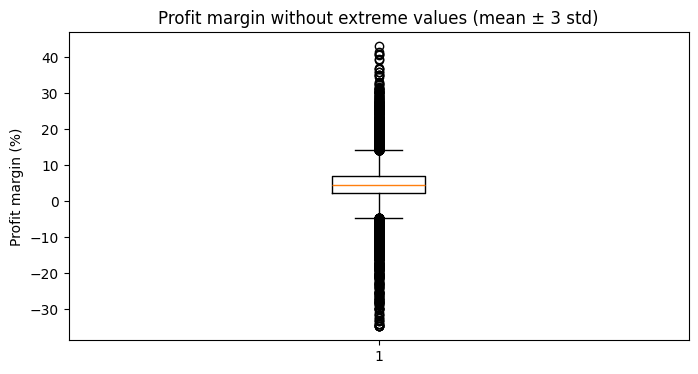

In [ ]:
# Boxplot without outliers (only for readability)
margin_no_outliers = profit_data[(profit_data["profit_margin"] >= lower) & (profit_data["profit_margin"] <= upper)]

plt.figure(figsize=(8, 4))
plt.boxplot(margin_no_outliers["profit_margin"])
plt.title("Profit margin without extreme values (mean ± 3 std)")
plt.ylabel("Profit margin (%)")
plt.show()

**Interpretation:** Without the extreme values, half of the company-years have a margin between about 2.4% and 7.1% (median 4.5%). Even so, many points remain outside the whiskers, especially on the negative side: losses can be much larger than typical profits.

Author(s): CAUCHE Noé, CERULLO Giuliano, DESCOUBES Yan, GOUINGUENET Mathis, KETTANI Nasser

We look at how the median revenue of the list changed over time.

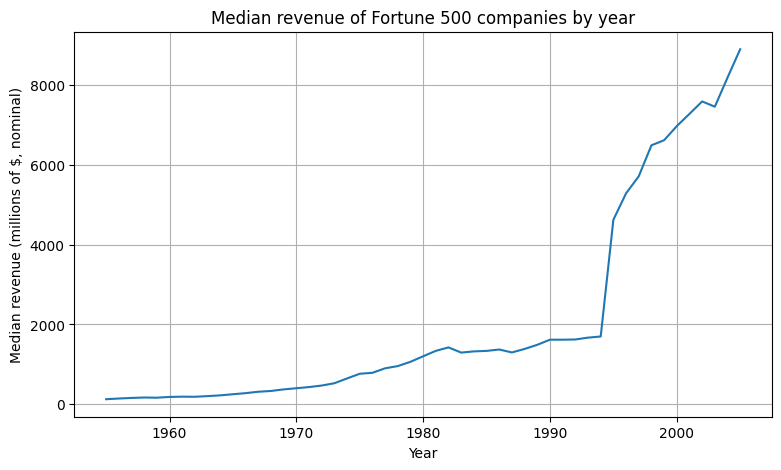

year
1955     123.30
1965     248.00
1975     762.05
1985    1335.90
1995    4626.15
2005    8904.65
Name: revenue, dtype: float64


In [ ]:
# Median revenue per year
median_revenue_year = df.groupby("year")["revenue"].median()

plt.figure(figsize=(9, 5))
plt.plot(median_revenue_year.index, median_revenue_year.values)
plt.title("Median revenue of Fortune 500 companies by year")
plt.xlabel("Year")
plt.ylabel("Median revenue (millions of $, nominal)")
plt.grid(True)
plt.show()

print(median_revenue_year[[1955, 1965, 1975, 1985, 1995, 2005]])

**Interpretation:** The median revenue increased from 123 million USD in 1955 to 8,905 million USD in 2005 (about 72 times, in nominal terms). Part of this increase reflects inflation, since values are not adjusted. This explains the two peaks of the log histogram: companies of the early and late years are on very different revenue scales.

### **5.2 Sub-question 1: Revenue growth**

Author(s): CAUCHE Noé, CERULLO Giuliano, DESCOUBES Yan, GOUINGUENET Mathis, KETTANI Nasser

We use the **median** growth: a few extreme values (up to +367%) would distort the mean. Growth is available only for companies present in two consecutive years (`growth` table).

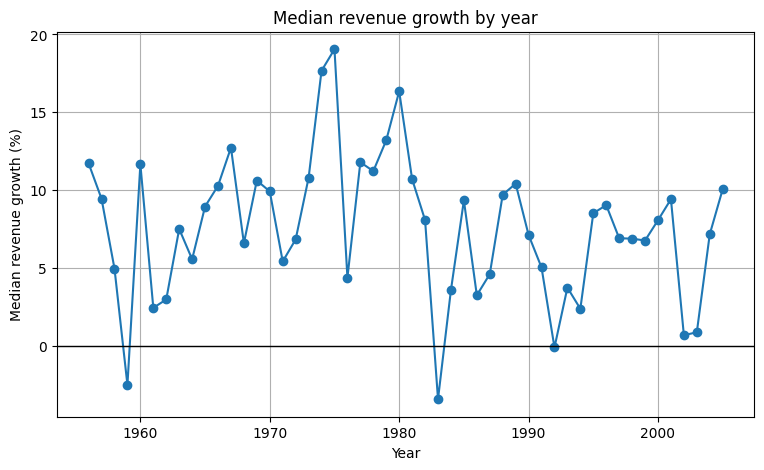

year
1983   -3.405341
1959   -2.486040
1992   -0.083673
Name: revenue_growth, dtype: float64
year
1980    16.351626
1974    17.669433
1975    19.051867
Name: revenue_growth, dtype: float64


In [ ]:
# Median revenue growth by year
growth_by_year = growth.groupby("year")["revenue_growth"].median()

plt.figure(figsize=(9, 5))
plt.plot(growth_by_year.index, growth_by_year.values, marker="o")
plt.axhline(0, color="black", linewidth=1)
plt.title("Median revenue growth by year")
plt.xlabel("Year")
plt.ylabel("Median revenue growth (%)")
plt.grid(True)
plt.show()

print(growth_by_year.sort_values().head(3))
print(growth_by_year.sort_values().tail(3))

**Interpretation:** In a typical year the median company grows by about 7.8% (median of the yearly values). Growth is highest in the 1970s (19.1% in 1975, 17.7% in 1974), a period of high inflation, and is negative or close to zero in 1959 (−2.5%), 1983 (−3.4%) and 1992 (−0.1%). These dips are close to U.S. recessions; since a list year usually reports the previous fiscal year, the dips appear one year after the recession.

                     median_growth (%)     n
previous_size_group                         
1-100                         7.090962  4854
101-200                       7.268922  4810
201-300                       7.762727  4695
301-400                       7.886677  4603
401-500                       9.703961  3982


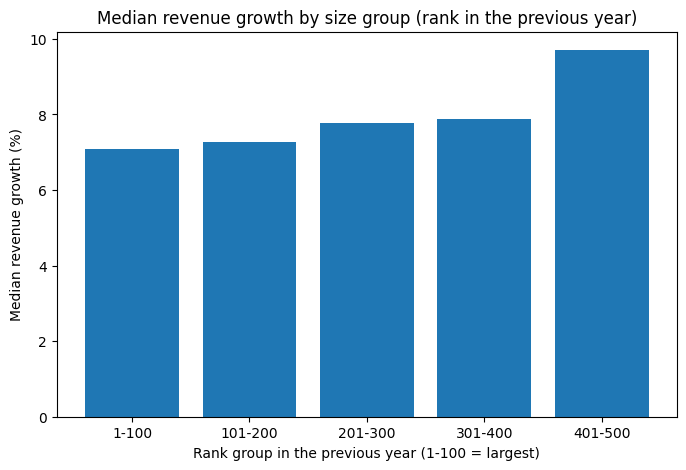

In [ ]:
# Median growth and number of observations by size group (measured BEFORE the growth)
median_growth_size = growth.groupby("previous_size_group", observed=True)["revenue_growth"].median()
n_growth_size = growth.groupby("previous_size_group", observed=True)["revenue_growth"].count()
print(pd.DataFrame({"median_growth (%)": median_growth_size, "n": n_growth_size}))

plt.figure(figsize=(8, 5))
plt.bar(median_growth_size.index, median_growth_size.values)
plt.title("Median revenue growth by size group (rank in the previous year)")
plt.xlabel("Rank group in the previous year (1-100 = largest)")
plt.ylabel("Median revenue growth (%)")
plt.show()

**Interpretation:** Larger companies grow more slowly: median growth is 7.1% for ranks 1-100 (n = 4,854) and rises steadily to 9.7% for ranks 401-500 (n = 3,982). However, the 401-500 group has fewer observations: companies in this group that shrink often fall out of the list, so their growth is not measured. The higher growth of small companies is therefore partly a selection effect (we only see those that stayed).

In [ ]:
# Median growth and number of observations by decade
median_growth_decade = growth.groupby("decade")["revenue_growth"].median()
n_growth_decade = growth.groupby("decade")["revenue_growth"].count()
pd.DataFrame({"median_growth (%)": median_growth_decade, "n": n_growth_decade})

,median_growth (%),n
decade,,
1950,5.998931,1858
1960,7.871486,4721
1970,10.948905,4712
1980,8.037847,4604
1990,5.505430,4329
2000,6.377287,2720


**Interpretation:** Median growth rises from 6.0% in the 1950s (only 1956–1959, n = 1,858) to a peak of 10.9% in the 1970s (n = 4,712), then falls to 8.0% in the 1980s and 5.5% in the 1990s (n = 4,329), with 6.4% in 2000–2005 (n = 2,720). The 1970s peak is associated with high inflation, because revenues are nominal.

**Answer to sub-question 1:** The typical Fortune 500 company grows by about 6–11% per year depending on the decade, and larger companies (higher rank) are associated with slower growth.

### **5.3 Sub-question 2: Profitability and risk**

Author(s): CAUCHE Noé, CERULLO Giuliano, DESCOUBES Yan, GOUINGUENET Mathis, KETTANI Nasser

We use only `profit_data` (rows with a known profit). The share of loss-making companies is computed as: loss-making companies / companies with a **known** profit. Missing profits are never counted as profits or losses.

First, we check how many profits are reported each year, to know how reliable each year is.

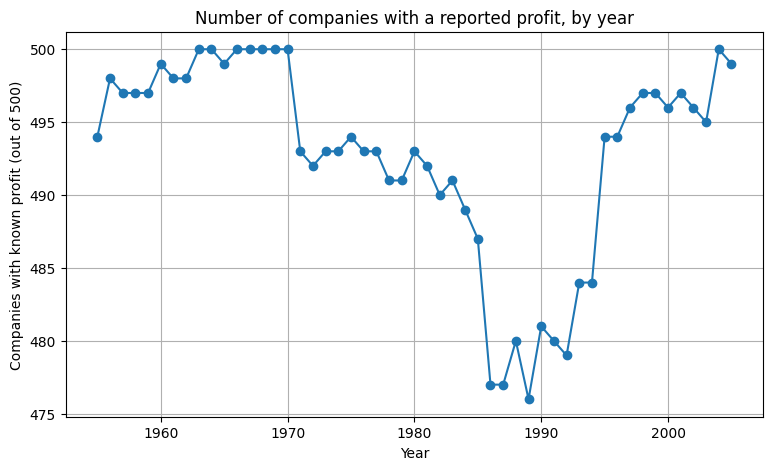

Lowest years:
year
1989    476
1986    477
1987    477
1992    479
1988    480
Name: profit, dtype: int64


In [ ]:
# Number of companies with a known profit, by year
reported_by_year = profit_data.groupby("year")["profit"].count()

plt.figure(figsize=(9, 5))
plt.plot(reported_by_year.index, reported_by_year.values, marker="o")
plt.title("Number of companies with a reported profit, by year")
plt.xlabel("Year")
plt.ylabel("Companies with known profit (out of 500)")
plt.grid(True)
plt.show()

print("Lowest years:")
print(reported_by_year.sort_values().head(5))

**Interpretation:** In most years at least 490 of the 500 profits are known. Missing values are concentrated between 1985 and 1994, when only about 476–484 profits are reported (lowest: 476 in 1989). Even in these years more than 95% of companies are covered, so the yearly loss shares remain informative, but they are slightly less precise in the late 1980s and early 1990s.

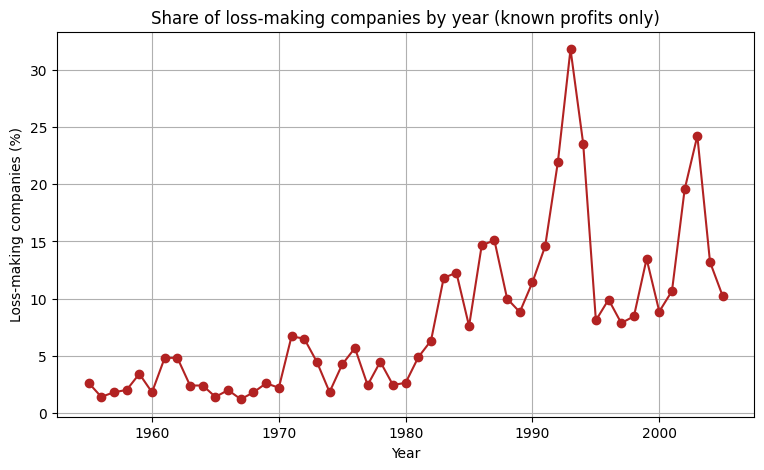

year
2002    19.556452
1992    21.920668
1994    23.553719
2003    24.242424
1993    31.818182
Name: loss_flag, dtype: float64


In [ ]:
# Share of loss-making companies by year (%)
loss_by_year = profit_data.groupby("year")["loss_flag"].mean() * 100

plt.figure(figsize=(9, 5))
plt.plot(loss_by_year.index, loss_by_year.values, marker="o", color="firebrick")
plt.title("Share of loss-making companies by year (known profits only)")
plt.xlabel("Year")
plt.ylabel("Loss-making companies (%)")
plt.grid(True)
plt.show()

print(loss_by_year.sort_values().tail(5))

**Interpretation:** Until the late 1970s losses were rare: usually below 5% of companies (e.g. 2.6% in 1955, 1.8% in 1960, 2.2% in 1970). From the 1980s the share rises clearly (7.6% in 1985, 11.4% in 1990) and reaches peaks of 31.8% in 1993, 23.6% in 1994 and 24.2% in 2003, around the early-1990s recession and the dot-com crash. In 2005 it is still 10.2%, about four times the level of the 1950s–1960s. The share of loss-making companies has therefore increased over time.

Author(s): CAUCHE Noé, CERULLO Giuliano, DESCOUBES Yan, GOUINGUENET Mathis, KETTANI Nasser

To test whether profit margins became more dispersed, we compute the median margin, the standard deviation of the margin and the number of observations by decade.

In [ ]:
# Median, standard deviation and count of profit margin by decade
median_margin_decade = profit_data.groupby("decade")["profit_margin"].median()
std_margin_decade = profit_data.groupby("decade")["profit_margin"].std()
n_margin_decade = profit_data.groupby("decade")["profit_margin"].count()

pd.DataFrame({"median_margin (%)": median_margin_decade,
              "std_margin (points)": std_margin_decade,
              "n": n_margin_decade})

,median_margin (%),std_margin (points),n
decade,,,
1950,4.755614,4.810153,2483
1960,4.811903,3.932720,4994
1970,4.328601,3.798343,4933
1980,4.417849,6.777783,4852
1990,4.112384,8.147904,4886
2000,4.300501,34.744502,2983


In [ ]:
# Same standard deviation, without the extreme values found in 5.1
std_margin_decade_no_out = margin_no_outliers.groupby("decade")["profit_margin"].std()
print(std_margin_decade_no_out)

decade
1950    4.281170
1960    3.932720
1970    3.677097
1980    5.173354
1990    6.474877
2000    7.801453
Name: profit_margin, dtype: float64


**Interpretation:** The typical company did not become less profitable: the median margin stays between 4.1% and 4.8% in every decade. However, margins became **more dispersed**: the standard deviation goes from 3.8 points in the 1970s to 6.8 in the 1980s, 8.1 in the 1990s and 34.7 in the 2000s. The 2000s value is inflated by a few extreme losses (e.g. JDS Uniphase 2002), but even without the outliers the standard deviation doubles, from 3.7 points in the 1970s to 7.8 in the 2000s. Profit margins became more dispersed: the gap between very profitable and loss-making companies widened.

            loss_share (%)     n
size_group                      
1-100             5.647383  5082
101-200           7.586345  5009
201-300           7.883735  5023
301-400           9.014925  5025
401-500           9.795673  4992


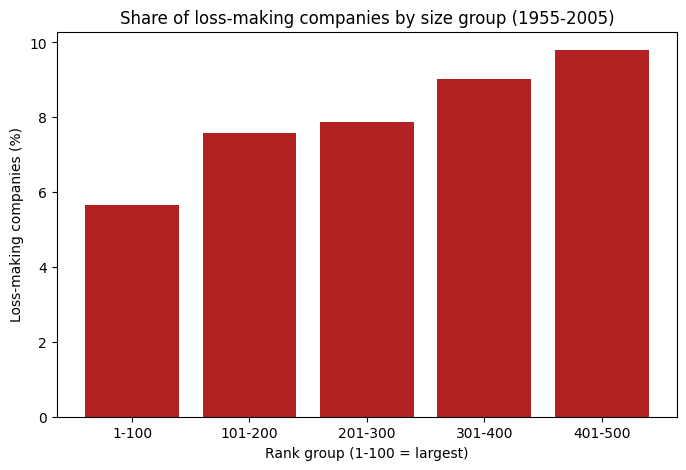

In [ ]:
# Share of losses and number of observations by size group
loss_by_size = profit_data.groupby("size_group", observed=True)["loss_flag"].mean() * 100
n_by_size = profit_data.groupby("size_group", observed=True)["loss_flag"].count()
print(pd.DataFrame({"loss_share (%)": loss_by_size, "n": n_by_size}))

plt.figure(figsize=(8, 5))
plt.bar(loss_by_size.index, loss_by_size.values, color="firebrick")
plt.title("Share of loss-making companies by size group (1955-2005)")
plt.xlabel("Rank group (1-100 = largest)")
plt.ylabel("Loss-making companies (%)")
plt.show()

**Interpretation:** Losses are more frequent among smaller companies of the list: 5.6% of company-years in ranks 1-100 (n = 5,082) against 9.8% in ranks 401-500 (n = 4,992), with a steady increase between the groups.

Author(s): CAUCHE Noé, CERULLO Giuliano, DESCOUBES Yan, GOUINGUENET Mathis, KETTANI Nasser

We combine decade and size group in a heatmap (as in L06): each cell is the share of loss-making companies (%) for that decade and rank group. `unstack()` turns the size groups into columns so the table can be drawn as a heatmap.

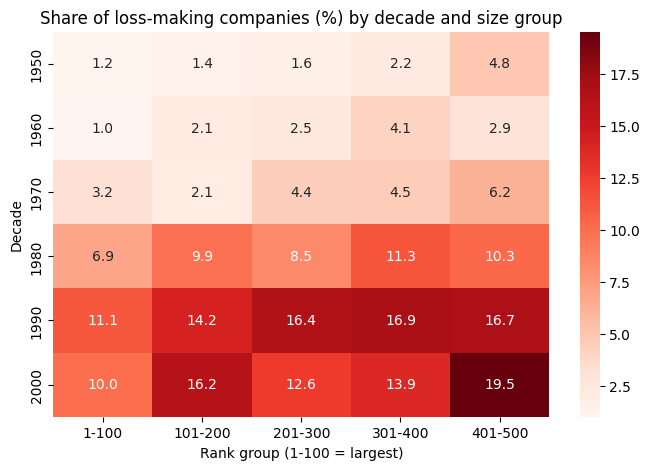

In [ ]:
# Share of losses by decade and size group
loss_decade_size = profit_data.groupby(["decade", "size_group"], observed=True)["loss_flag"].mean().unstack() * 100

plt.figure(figsize=(8, 5))
sns.heatmap(loss_decade_size, annot=True, fmt=".1f", cmap="Reds")
plt.title("Share of loss-making companies (%) by decade and size group")
plt.xlabel("Rank group (1-100 = largest)")
plt.ylabel("Decade")
plt.show()

**Interpretation:** The increase in losses affects **all** size groups. In the 1950s–1960s losses were between 1.0% and 4.8% in every group; in the 1990s they reached 11.1% for ranks 1-100 and 14–17% for the other groups. In the 2000s the highest share is in ranks 401-500 (19.5%), but even the largest companies (1-100) show 10.0%. Lower-ranked companies are generally more affected, but being among the largest no longer means being protected from losses. (Note: the 1950s include only 1955–1959 and the 2000s only 2000–2005.)

**Answer to sub-question 2:** The share of loss-making companies increased strongly from the 1980s, margins became more dispersed while the median margin stayed around 4–5%, and lower-ranked companies are more often in loss.

### **5.4 Sub-question 3: Five-year retention over time**

Author(s): CAUCHE Noé, CERULLO Giuliano, DESCOUBES Yan, GOUINGUENET Mathis, KETTANI Nasser

We use the `retention` table (starting years 1955–2000, duplicated names excluded). The retention rate of a year is the % of companies on the list that year that are also on the list five years later.

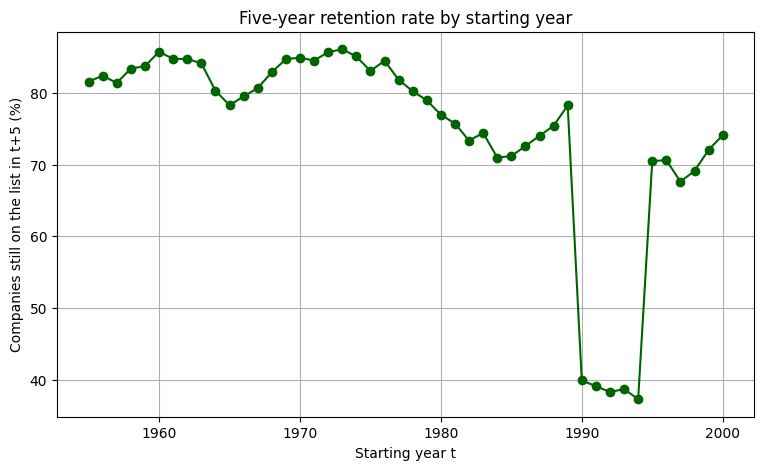

year
1994    37.298387
1992    38.306452
1993    38.709677
1991    39.112903
1990    39.919355
Name: survived_5y, dtype: float64


In [ ]:
# Retention rate by starting year (%)
retention_by_year = retention.groupby("year")["survived_5y"].mean() * 100

plt.figure(figsize=(9, 5))
plt.plot(retention_by_year.index, retention_by_year.values, marker="o", color="darkgreen")
plt.title("Five-year retention rate by starting year")
plt.xlabel("Starting year t")
plt.ylabel("Companies still on the list in t+5 (%)")
plt.grid(True)
plt.show()

print(retention_by_year.sort_values().head(5))

**Interpretation:** From 1955 to the late 1970s retention is high and stable, around 80–86% (e.g. 81.6% in 1955, 84.9% in 1970). It declines in the 1980s (71.2% in 1985). For the starting years 1990–1994 it collapses to 37–40%, then returns to about 68–74% for 1995–2000.

The collapse of 1990–1994 is too sudden to be explained by company performance alone. For these years, year t+5 is 1995 or later. In 1995 Fortune changed its methodology: until 1994 the list ranked only **industrial** companies, and from 1995 it combined industrial and **service** companies (retailers, banks, telecoms, etc.). Many industrial companies were pushed out of the list by large service companies. We check this in the data.

In [ ]:
# Companies on the 1995 list that were NOT on the 1994 list
names_1994 = df[df["year"] == 1994]["company"]
new_1995 = df[(df["year"] == 1995) & (df["company"].isin(names_1994) == False)]
print("New names in 1995:", new_1995.shape[0])
new_1995[["rank", "company"]].head(10)

New names in 1995: 290


,rank,company
20003,4,Wal-Mart Stores
20004,5,AT&T
20008,9,Sears Roebuck
20011,12,State Farm Insurance Cos
20012,13,Prudential Ins. Co. of America
20014,15,Kmart Holding
20016,17,Citicorp
20022,23,ITT Industries
20024,25,Kroger
20025,26,American Intl. Group


**Interpretation and decision:** 290 of the 500 companies of 1995 were not on the 1994 list, against about 30–50 new names in a normal year. Many of them are service companies (e.g. AT&T, American Express, Aetna). This confirms that the 1995 change of methodology creates artificial "exits" for the starting years 1990–1994.

To compare periods fairly, we create `retention_robust`, which **excludes the starting years 1990–1994**. We use it for the comparisons by decade and for sub-question 4.

*Alternative:* keep all years and simply report the problem. The 1990s average would then be strongly biased downward (54% instead of 70%).

In [ ]:
# Exclude starting years affected by the 1995 change of methodology
retention_robust = retention[(retention["year"] < 1990) | (retention["year"] > 1994)].copy()
print("Rows in retention:", retention.shape[0])
print("Rows in retention_robust:", retention_robust.shape[0])
print("Retention rate (%):", retention_robust["survived_5y"].mean() * 100)

Rows in retention: 22790
Rows in retention_robust: 20310
Retention rate (%): 79.01526341703594


        retention (%)     n
decade                     
1950        82.470919  2493
1960        82.544796  4967
1970        83.457887  4951
1980        74.268416  4955
1990        69.967400  2454
2000        74.081633   490


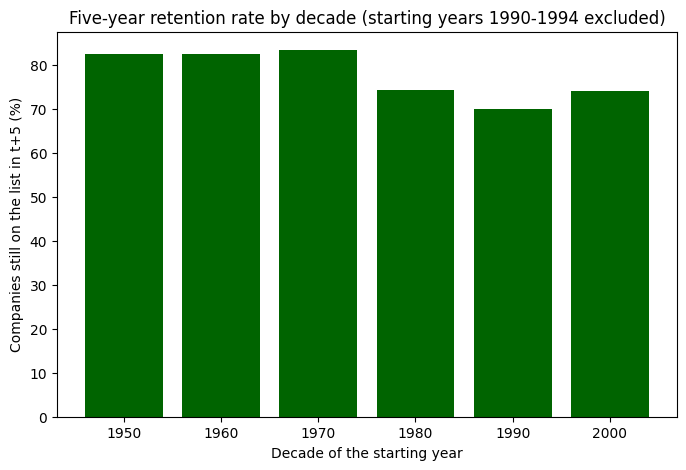

In [ ]:
# Retention rate and number of observations by decade
retention_decade = retention_robust.groupby("decade")["survived_5y"].mean() * 100
n_retention_decade = retention_robust.groupby("decade")["survived_5y"].count()
print(pd.DataFrame({"retention (%)": retention_decade, "n": n_retention_decade}))

plt.figure(figsize=(8, 5))
plt.bar(retention_decade.index.astype(str), retention_decade.values, color="darkgreen")
plt.title("Five-year retention rate by decade (starting years 1990-1994 excluded)")
plt.xlabel("Decade of the starting year")
plt.ylabel("Companies still on the list in t+5 (%)")
plt.show()

**Interpretation:** Retention is stable around 82–83% in the 1950s (n = 2,493), 1960s (n = 4,967) and 1970s (n = 4,951), then falls to 74.3% in the 1980s (n = 4,955) and 70.0% in the 1990s (only 1995–1999, n = 2,454). The value for 2000 (74.1%) is based on a single starting year (n = 490). Note that the 1950s contain only 1955–1959.

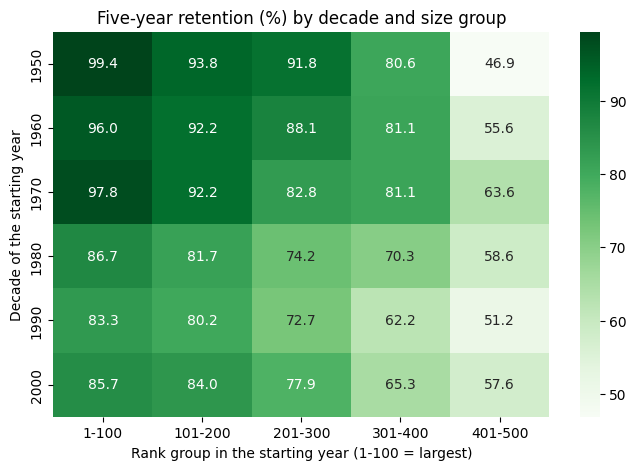

In [ ]:
# Retention by decade and size group
retention_decade_size = retention_robust.groupby(["decade", "size_group"], observed=True)["survived_5y"].mean().unstack() * 100

plt.figure(figsize=(8, 5))
sns.heatmap(retention_decade_size, annot=True, fmt=".1f", cmap="Greens")
plt.title("Five-year retention (%) by decade and size group")
plt.xlabel("Rank group in the starting year (1-100 = largest)")
plt.ylabel("Decade of the starting year")
plt.show()

**Interpretation:** Retention is strongly associated with rank: in every decade the largest companies (1-100) are much more likely to remain (83–99%) than ranks 401-500 (47–64%). The decline over time is visible in almost all groups: for ranks 1-100 retention falls from 99.4% in the 1950s to 83–87% from the 1980s; for ranks 301-400 from about 81% to 62–70%.

**Answer to sub-question 3:** Yes. Excluding the years distorted by the 1995 change of methodology, five-year retention fell from about 83% (1950s–1970s) to 70–74% (1980s–2000). Staying on the list became harder, even for the largest companies.

### **5.5 Sub-question 4: Growth, profit and retention**

Author(s): CAUCHE Noé, CERULLO Giuliano, DESCOUBES Yan, GOUINGUENET Mathis, KETTANI Nasser

We build the table `analysis` by combining retention (`retention_robust`) with revenue growth (`growth`), using an **inner** merge on company and year. Each step reduces the sample:
1. `retention_robust`: 20,310 rows;
2. inner merge with `growth`: only companies that also appear in the previous year (so 1955 drops out);
3. only rows with a known profit.

We then create two simple variables: `positive_growth` (revenue growth > 0) and `profitable` (profit > 0). The False categories are called "non-positive" growth and "non-profitable" (they include zero values, not only negative ones).

In [ ]:
# Combine retention and growth (only the columns we need from growth)
analysis = retention_robust.merge(growth[["company", "year", "revenue_growth"]], on=["company", "year"], how="inner")
print("After merge with growth:", analysis.shape[0])

# Keep only rows with a known profit
analysis = analysis[analysis["profit"].isnull() == False].copy()
print("After removing missing profits:", analysis.shape[0])

analysis["positive_growth"] = analysis["revenue_growth"] > 0
analysis["profitable"] = analysis["profit"] > 0
analysis.head()

After merge with growth: 18354
After removing missing profits: 18124


,year,rank,company,revenue,profit,profit_margin,decade,size_group,in_list_5y_later,survived_5y,revenue_growth,positive_growth,profitable
0,1956,1,General Motors,12443.3,1189.5,9.559361,1950,1-100,1.0,True,26.668703,True,True
1,1956,2,Exxon Mobil,6272.4,709.3,11.308271,1950,1-100,1.0,True,10.792384,True,True
2,1956,4,U.S. Steel,4097.7,370.1,9.031896,1950,1-100,1.0,True,26.067561,True,True
3,1956,5,Chrysler,3466.2,100.1,2.887889,1950,1-100,1.0,True,67.319946,True,True
4,1956,6,General Electric,3095.4,200.9,6.490276,1950,1-100,1.0,True,4.606130,True,True


In [ ]:
# Retention by growth and by profitability, with number of observations
ret_growth = analysis.groupby("positive_growth")["survived_5y"].mean() * 100
n_growth = analysis.groupby("positive_growth")["survived_5y"].count()
print(pd.DataFrame({"retention (%)": ret_growth, "n": n_growth}))

ret_profit = analysis.groupby("profitable")["survived_5y"].mean() * 100
n_profit = analysis.groupby("profitable")["survived_5y"].count()
print(pd.DataFrame({"retention (%)": ret_profit, "n": n_profit}))

                 retention (%)      n
positive_growth                      
False                72.880879   3551
True                 82.556783  14573
            retention (%)      n
profitable                      
False           60.119048   1008
True            81.870764  17116


**Interpretation:** Companies with positive growth remain on the list five years later more often (82.6%, n = 14,573) than companies with non-positive growth (72.9%, n = 3,551): about 10 points more. The gap is larger for profitability: 81.9% for profitable companies (n = 17,116) against 60.1% for non-profitable ones (n = 1,008), about 22 points.

                            retention (%)      n
positive_growth profitable                      
False           False           56.321839    522
                True            75.734566   3029
True            False           64.197531    486
                True            83.190175  14087


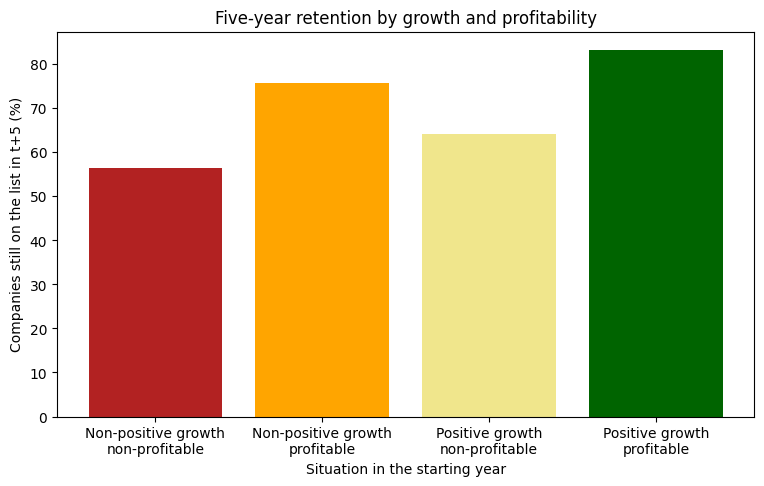

In [ ]:
# Retention for the 4 combinations of growth and profitability
ret_combo = analysis.groupby(["positive_growth", "profitable"])["survived_5y"].mean() * 100
n_combo = analysis.groupby(["positive_growth", "profitable"])["survived_5y"].count()
print(pd.DataFrame({"retention (%)": ret_combo, "n": n_combo}))

labels = ["Non-positive growth\nnon-profitable", "Non-positive growth\nprofitable",
          "Positive growth\nnon-profitable", "Positive growth\nprofitable"]

plt.figure(figsize=(9, 5))
plt.bar(labels, ret_combo.values, color=["firebrick", "orange", "khaki", "darkgreen"])
plt.title("Five-year retention by growth and profitability")
plt.xlabel("Situation in the starting year")
plt.ylabel("Companies still on the list in t+5 (%)")
plt.show()

**Interpretation:** Retention increases step by step: 56.3% for companies that neither grew nor made a profit (n = 522), 64.2% for growing but non-profitable ones (n = 486), 75.7% for profitable but non-growing ones (n = 3,029) and 83.2% for companies that were both growing and profitable (n = 14,087). Profitability is associated with a larger difference than growth. The two "non-profitable" groups are small (about 500 companies each), so their rates are less precise.

Author(s): CAUCHE Noé, CERULLO Giuliano, DESCOUBES Yan, GOUINGUENET Mathis, KETTANI Nasser

Larger companies are more often profitable and more often retained. To check that the association is not only a size effect, we repeat the comparison **within each size group**.

In [ ]:
# Retention by size group and growth
print((analysis.groupby(["size_group", "positive_growth"], observed=True)["survived_5y"].mean().unstack() * 100).round(1))
print(analysis.groupby(["size_group", "positive_growth"], observed=True)["survived_5y"].count().unstack())

positive_growth  False  True 
size_group                   
1-100             89.6   93.7
101-200           83.6   89.7
201-300           76.3   83.6
301-400           69.1   78.3
401-500           47.3   61.3
positive_growth  False  True 
size_group                   
1-100              644   3211
101-200            708   3089
201-300            763   3025
301-400            725   2967
401-500            711   2281


In [ ]:
# Retention by size group and profitability
print((analysis.groupby(["size_group", "profitable"], observed=True)["survived_5y"].mean().unstack() * 100).round(1))
print(analysis.groupby(["size_group", "profitable"], observed=True)["survived_5y"].count().unstack())

profitable  False  True 
size_group              
1-100        88.1   93.2
101-200      70.7   89.5
201-300      66.3   83.0
301-400      56.6   77.9
401-500      34.9   60.0
profitable  False  True 
size_group              
1-100         134   3721
101-200       181   3616
201-300       208   3580
301-400       244   3448
401-500       241   2751


**Interpretation:** The association remains in every size group, so it is not only explained by size. Positive growth is associated with higher retention by 4 points in ranks 1-100 (93.7% vs 89.6%) and by 14 points in ranks 401-500 (61.3% vs 47.3%). The difference for profitability is even larger: from 5 points in ranks 1-100 (93.2% vs 88.1%) to 25 points in ranks 401-500 (60.0% vs 34.9%). Growth and profit matter most for companies near the bottom of the list, which can easily fall below rank 500. Non-profitable groups are small (134–244 companies per size group).

**Answer to sub-question 4:** Yes. Growing and, above all, profitable companies appear more often on the list five years later, and this association holds within every size group. This is an association, not a causal effect: for example, a profitable company may also be in a stronger industry.

## **6\. Summary**

Author(s): CAUCHE Noé, CERULLO Giuliano, DESCOUBES Yan, GOUINGUENET Mathis, KETTANI Nasser

**Sub-question 1 – Growth.** The typical Fortune 500 company grows by about 7.8% per year (median of yearly medians, 1956–2005, nominal). Growth was highest in the 1970s (10.9% median, a period of high inflation) and lowest in the 1990s (5.5%). Larger companies are associated with slower growth: 7.1% for ranks 1-100 against 9.7% for ranks 401-500 (section 5.2, bar chart by size group). *Limit:* growth is measured only for companies present in two consecutive years, so companies that shrink and leave the list are partly missing.

**Sub-question 2 – Profitability and risk.** The share of loss-making companies rose from below 5% in most years before 1980 to 11.4% in 1990, with peaks of 31.8% in 1993 and 24.2% in 2003 (section 5.3, line chart). The median margin stayed stable (4.1–4.8% in every decade), but margins became more dispersed: the standard deviation doubled from 3.7 points in the 1970s to 7.8 in the 2000s (without outliers). Lower-ranked companies are more often in loss (9.8% for ranks 401-500 vs 5.6% for ranks 1-100). *Limit:* 369 profits are missing, mostly in 1985–1994.

**Sub-question 3 – Retention over time.** Five-year retention fell from about 83% for starting years in the 1950s–1970s to 74.3% in the 1980s and 70.0% in 1995–1999 (section 5.4, bar chart by decade), and the decline is visible even for ranks 1-100. *Limit:* starting years 1990–1994 are excluded because the 1995 change of methodology (service companies added to the list) creates artificial exits.

**Sub-question 4 – Growth, profit and retention.** Companies that were both growing and profitable are still on the list five years later in 83.2% of cases (n = 14,087), against 56.3% for companies that were neither (n = 522) (section 5.5, bar chart of the 4 combinations). Profitability is associated with a larger difference (+22 points) than growth (+10 points), and both associations hold within every size group. *Limit:* non-profitable groups are small, and we cannot control for industry.

### **6.1 Answer to the main question**
Revenue growth and, above all, profitability **are associated with** remaining in the Fortune 500 five years later, in every size group. At the same time, staying on the list **became harder over time**: retention fell by about 10 points between the 1950s–1970s and the 1980s–2000, while losses became more frequent and margins more dispersed. These are descriptive associations, not causal effects.

### **6.2 Managerial implications**
- **Rank matters more than any single indicator:** companies near the bottom of the list (ranks 401-500) remain only about half of the time, so a small drop in revenue scale can be enough to exit. Companies close to rank 500 should monitor their revenue scale relative to the threshold.
- **Being large is less protective than before:** since the 1980s even the top 100 companies leave the list more often and make losses more often.
- **Profitability is associated with staying on the list, but does not guarantee it:** about 17% of companies that were growing and profitable were not on the list five years later.
- **An exit from the list is not a failure:** it can reflect an acquisition, a merger, a change of name or a change in Fortune's methodology.

### **6.3 Limitations**

Author(s): CAUCHE Noé, CERULLO Giuliano, DESCOUBES Yan, GOUINGUENET Mathis, KETTANI Nasser

- **Nominal values:** revenues and profits are not adjusted for inflation, so growth in the 1970s is overstated in real terms.
- **Missing profits:** 369 profits are missing (mostly 1985–1994); they are excluded from profit analyses.
- **Matching on exact names:** a change of name, merger or acquisition is counted as an exit.
- **Duplicate company-year pairs:** 7 company names (238 rows) are excluded from growth and retention.
- **Change of methodology in 1995:** service companies were added to the list; starting years 1990–1994 are excluded from the retention comparisons, and the composition of the list before and after 1995 is different.
- **Growth only for consecutive appearances:** companies that leave the list are partly missing from the growth analysis (selection effect).
- **Repeated observations:** the same company appears in many years, so observations are not independent.
- **Incomplete decades:** the 1950s contain only 1955–1959 and the 2000s only 2000–2005 (only 2000 for retention).
- **Retention definition:** presence in year t+5, not continuous presence over the five years.
- **Few variables:** no industry, assets or employees, so we cannot separate the effect of the sector.
- **Data end in 2005.**

## **7\. Declaration of Generative AI and AI-assisted technologies in the writing process**

During the preparation of this work we used Claude (Anthropic) in order to structure the notebook and check the Python code, as well as drafting explanations and interpretations. After using this tool/service, we reviewed and edited the content as needed and take full responsibility for the content of the publication.

This tool/service was mainly used for:
- statistical analysis and interpretation;
- debug code.

## **8\. References**

- Dataset: Fortune 500 companies 1955–2005, repository *cybersamx/notebooks* on GitHub. https://raw.githubusercontent.com/cybersamx/notebooks/master/data/fortune500.csv
- Bouraga, S. *Python* course slides L01–L06 (Introduction; Getting Started with Python; Introduction to Pandas; Data Visualization; Exploratory Data Analysis; Working with Dates), EM Normandie.
- Stewart, T. A. (1995, May 15). A New 500 for the New Economy. *Fortune*. https://fortune.com/1995/05/15/a-new-500-for-the-new-economy
- Fortune (2025). Fortune Archives: The year the Fortune 500 recalibrated. https://fortune.com/2025/06/08/fortune-archives-the-year-the-fortune-500-recalibrated/
- pandas, matplotlib, seaborn and numpy documentation.